# Pumping-station levels (gemaal in- en uitstroompeil): data and outliers

**Local notebook** (not a Databricks job). It reads the CSVs in `pastas/data/stresses/` and uses the cleaning in
`research/accepted/stresses.py`, the same code the Pastas fits use, so what is plotted here is what the models get.

**The data.** HHNK 15-minute water levels (m NAP, CET/CEST wall clock) at five pumping stations. They were delivered as xlsx on
2026-11-24 and converted to CSV with the columns `time, instroompeil, uitstroompeil`. The values are unchanged; the round trip was checked exactly.

| polder | station | file | location |
|---|---|---|---|
| Beemster | Jacobus Bouman | `Beemster_Jacobus_Bouman.csv` | Oostdijk, east side |
| Beemster | Wouter Sluis | `Beemster_Wouter_Sluis.csv` | Westdijk, west side |
| Purmer | Stedelijk | `Purmer_Stedelijk.csv` | the only Purmer record |
| Heerhugowaard | Hensbroek | `Heerhugowaard_Hensbroek.csv` | north-east |
| Heerhugowaard | Huygendijk | `Heerhugowaard_Huygendijk.csv` | south-west (original columns `waterhoogte_krooshek`, `waterhoogte_boezem`) |

* **instroompeil** is the polder side of the pump: the polder water level. That is about −5.0 m NAP in the Beemster, −4.3 in the Purmer, and −3.4 / −3.9 in Heerhugowaard.
* **uitstroompeil** is the boezem side: the Schermerboezem, about −0.5 m NAP.

**Cleaning** (per record and column, `stresses.clean_gemaal`):
1. Missing values are dropped. Duplicate stamps are averaged: the CET/CEST fall-back hour, and 2018–2020 in Huygendijk, which is in the file twice with identical values.
2. **band**: a value more than 0.40 m from the record's median, such as a sensor reading the wrong side, or a dropout.
3. **spike**: a value more than 0.10 m from the centred 3-hour running median.
4. **flat**: a value inside a run of identical values longer than 2 days (a frozen sensor).
5. The daily mean is kept if at least 48 of the 96 quarter-hours remain → `data/stresses/gemaal_<station>_daily.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

PASTAS = Path.cwd().resolve()
while not (PASTAS / "research").is_dir():          # run from anywhere inside pastas/
    PASTAS = PASTAS.parent
for p in (PASTAS, PASTAS / "src"):
    sys.path.insert(0, str(p))
from research.accepted import stresses

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOURS = {"raw": "#4a6fa5", "kept": "#4a6fa5", "daily": "#1b1b1b",
           "band": "#d1495b", "spike": "#e09f3e", "flat": "#8e44ad"}

RAW = {name: stresses.gemaal_raw(name).set_index("time") for name in stresses.GEMALEN}
CLEAN = {(name, col): stresses.clean_gemaal(RAW[name][col])
         for name in stresses.GEMALEN for col in stresses.COLUMNS}
DAILY = {name: stresses.gemaal_daily(name, refresh=True) for name in stresses.GEMALEN}

# The period of the validated groundwater series per polder (what the models are calibrated on).
where = stresses.positions()
validated = pd.read_csv(PASTAS / "results_export" / "valid_pastas" / "fit_metrics.csv",
                        usecols=["meetreeks_id", "tmin", "tmax"])
validated = validated.drop_duplicates("meetreeks_id").join(where[["polder"]], on="meetreeks_id")
CALIBRATION = {p: (pd.Timestamp(g["tmin"].min()), pd.Timestamp(g["tmax"].max()))
               for p, g in validated.groupby("polder")}
CALIBRATION

{'Beemster': (Timestamp('2024-08-14 00:00:00'),
  Timestamp('2026-10-12 00:00:00')),
 'Purmer': (Timestamp('2024-11-11 00:00:00'),
  Timestamp('2026-10-12 00:00:00'))}

## Summary per record
Removed values per reason, and how many days are left for the models.

In [2]:
rows = []
for name, (polder, file, *_) in stresses.GEMALEN.items():
    for col in stresses.COLUMNS:
        raw = RAW[name][col]
        kept, removed = CLEAN[(name, col)]
        reasons = removed["reason"].value_counts()
        rows.append({"polder": polder, "station": name, "column": col,
                     "from": raw.dropna().index.min().date(), "to": raw.dropna().index.max().date(),
                     "values": int(raw.notna().sum()),
                     "duplicate stamps": int(raw.dropna().index.duplicated().sum()),
                     "band": int(reasons.get("band", 0)), "spike": int(reasons.get("spike", 0)),
                     "flat": int(reasons.get("flat", 0)),
                     "removed %": round(100 * len(removed) / max(len(kept) + len(removed), 1), 2),
                     "median (m NAP)": round(kept.median(), 3),
                     "daily std (cm)": round(100 * DAILY[name][col].std(), 1),
                     "days": int(DAILY[name][col].count())})
pd.DataFrame(rows)

,polder,station,column,from,to,values,duplicate stamps,band,spike,flat,removed %,median (m NAP),daily std (cm),days
0,Beemster,jacobus_bouman,instroompeil,2019-01-14,2026-11-24,270738,32,0,101,0,0.04,-5.032,2.9,2828
1,Beemster,jacobus_bouman,uitstroompeil,2019-01-14,2026-11-24,270750,32,0,1,0,0.00,-0.477,2.1,2828
2,Beemster,wouter_sluis,instroompeil,2018-04-01,2026-11-24,300647,36,3,517,0,0.17,-5.027,3.5,3148
3,Beemster,wouter_sluis,uitstroompeil,2018-04-01,2026-11-24,300149,36,26,0,0,0.01,-0.466,2.1,3142
4,Purmer,purmer_stedelijk,instroompeil,2018-12-25,2026-11-24,275884,32,1,1,0,0.00,-4.284,2.1,2886
5,Purmer,purmer_stedelijk,uitstroompeil,2018-12-25,2026-11-24,275884,32,796,0,0,0.29,-0.483,2.6,2877
6,Heerhugowaard,hensbroek,instroompeil,2018-06-04,2026-11-24,295409,36,1,3,0,0.00,-3.411,4.3,3091
7,Heerhugowaard,hensbroek,uitstroompeil,2018-06-04,2026-11-24,295485,36,1,0,0,0.00,-0.594,2.5,3091
8,Heerhugowaard,huygendijk,instroompeil,2002-02-02,2026-11-24,941871,109152,135,7,0,0.02,-3.943,3.7,8683
9,Heerhugowaard,huygendijk,uitstroompeil,2003-01-01,2026-11-24,915589,109152,719,214,0,0.12,-0.483,6.0,8405


## Per polder: the series we have, and the outliers removed

Each figure shows both stations of a polder: the daily means after cleaning as lines, and the removed 15-minute values as dots, coloured by reason.
The grey band is the calibration period of the polder's validated groundwater series. Heerhugowaard has no validated series yet.
Removed values far outside the kept range are drawn at the panel edge.

**About the "spikes" in the instroompeil.** Most of them are not sensor errors. They are real dips at the pump inlet, a local
drawdown while the pumps run, which is why they cluster in wet winters, as at Wouter Sluis in 2020–2021. They are removed
because the drawdown is local to the pump and not the polder level a dike piezometer sees. That is 0.04–0.17 % of the values,
and it hardly changes the daily means.

In [3]:
def polder_overview(polder: str) -> None:
    names = [n for n, v in stresses.GEMALEN.items() if v[0] == polder]
    fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
    for ax, col in zip(axes, stresses.COLUMNS):
        kept_all = pd.concat([CLEAN[(n, col)][0] for n in names])
        low, high = kept_all.min(), kept_all.max()
        pad = 0.1 * (high - low)
        for i, name in enumerate(names):
            colour = ["#4a6fa5", "#2a9d8f"][i]
            ax.plot(DAILY[name].index, DAILY[name][col], lw=0.8, color=colour, label=f"{name} (daily, cleaned)")
            removed = CLEAN[(name, col)][1]
            for reason, group in removed.groupby("reason"):
                # values far outside the kept range are drawn at the panel edge
                ax.scatter(group.index, group["value"].clip(low - pad, high + pad), s=9, color=COLOURS[reason],
                           zorder=3, marker="ox"[i], label=f"{name}: removed ({reason}, {len(group)})")
        ax.set_ylim(low - 1.5 * pad, high + 1.5 * pad)
        if polder in CALIBRATION:
            ax.axvspan(*CALIBRATION[polder], color="0.88", zorder=0, label="validated groundwater series")
        ax.set_ylabel(f"{col} (m NAP)")
        ax.legend(fontsize=7, ncol=3, loc="upper left")
    axes[0].set_title(f"{polder}: pumping-station levels")
    axes[-1].xaxis.set_major_locator(mdates.YearLocator(2 if polder == "Heerhugowaard" else 1))
    fig.tight_layout()
    plt.show()

### Beemster

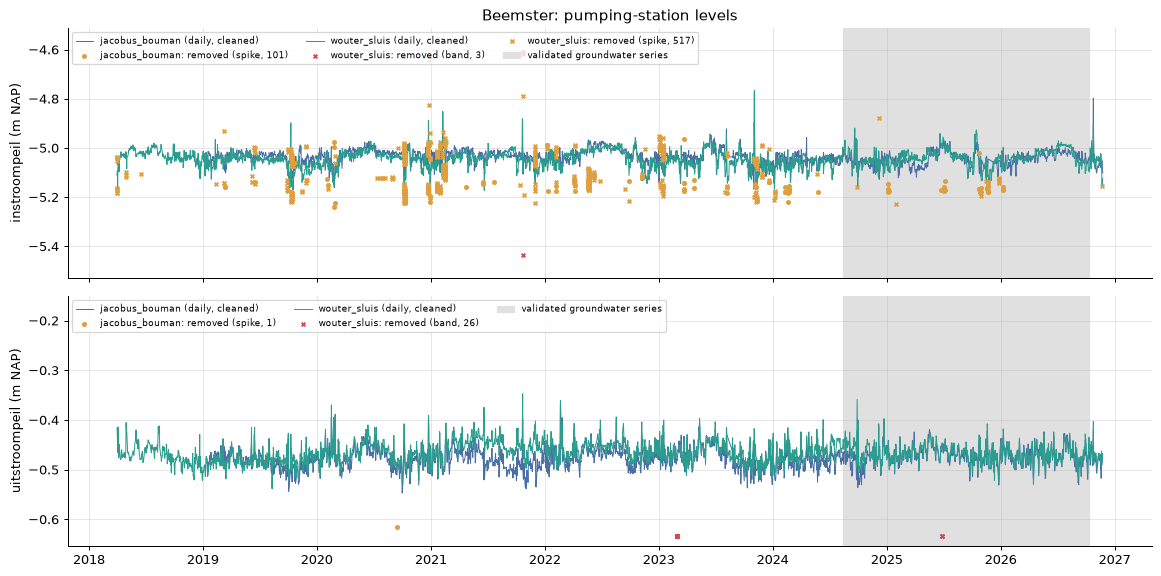

In [4]:
polder_overview("Beemster")

### Purmer

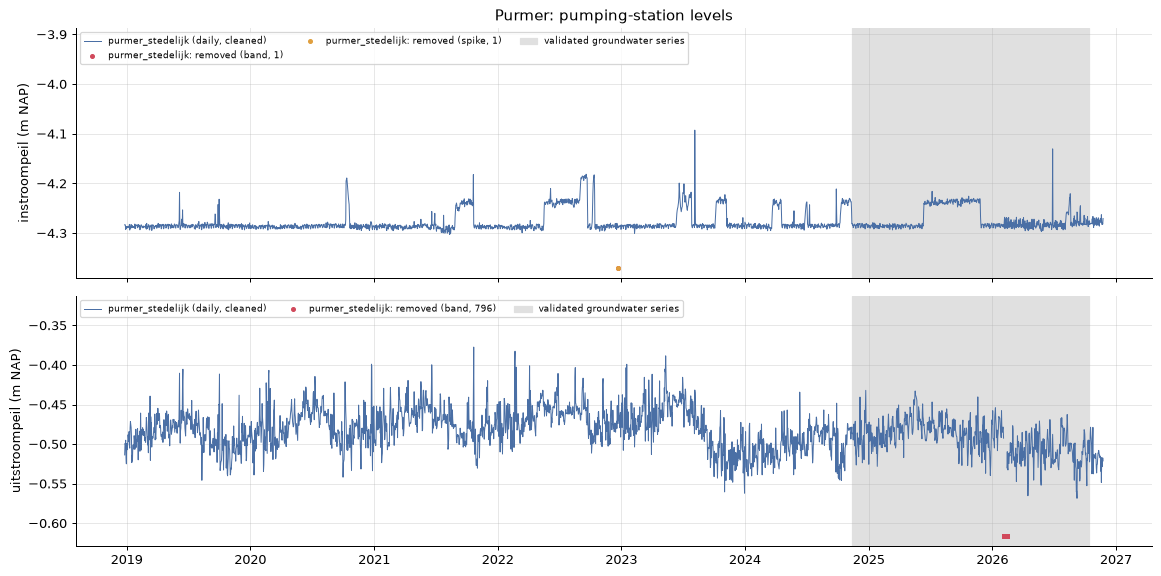

In [5]:
polder_overview("Purmer")

### Heerhugowaard

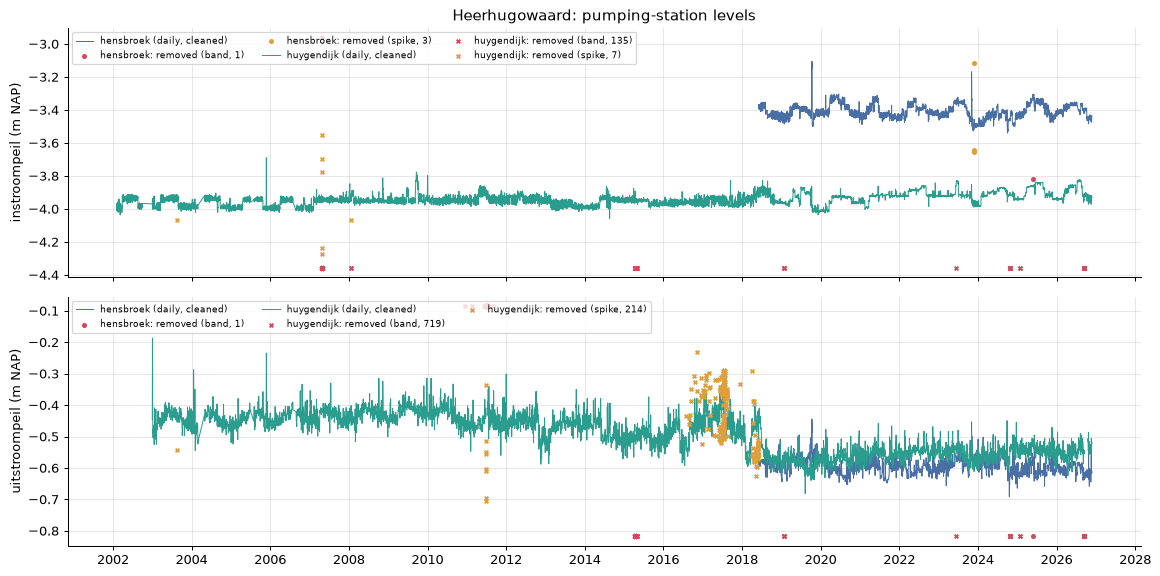

In [6]:
polder_overview("Heerhugowaard")

## Per input file: raw data, and the cleaned series with the outliers removed

Every file gets the same four panels:
* **top**: the raw 15-minute instroompeil and uitstroompeil, as delivered;
* **bottom**: what is kept (blue), the daily mean the models use (black), and the removed values, coloured by reason.

The bottom panels zoom to the kept range, so a removed value far outside it is drawn at the panel edge. Its count is in the legend.
The top panels show every value.

In [7]:
def show_file(name: str) -> None:
    polder, file, *_ = stresses.GEMALEN[name]
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    for j, col in enumerate(stresses.COLUMNS):
        raw = RAW[name][col].dropna().sort_index()
        kept, removed = CLEAN[(name, col)]
        top, bottom = axes[0, j], axes[1, j]
        top.plot(raw.index, raw, lw=0.4, color=COLOURS["raw"], rasterized=True)
        top.set_title(f"{col}: raw ({len(raw):,} values)")
        top.set_ylabel("m NAP")
        bottom.plot(kept.index, kept, lw=0.4, color=COLOURS["kept"], rasterized=True, label="kept (15 min)")
        bottom.plot(DAILY[name].index, DAILY[name][col], lw=0.8, color=COLOURS["daily"], label="daily mean")
        low, high = kept.min(), kept.max()
        pad = 0.1 * (high - low)
        for reason, group in removed.groupby("reason"):
            shown = group["value"].clip(low - pad, high + pad)
            bottom.scatter(group.index, shown, s=10, color=COLOURS[reason], zorder=3,
                           label=f"removed: {reason} ({len(group)})")
        bottom.set_ylim(low - 1.5 * pad, high + 1.5 * pad)
        share = 100 * len(removed) / (len(kept) + len(removed))
        bottom.set_title(f"{col}: cleaned, {len(removed):,} removed ({share:.2f} %)")
        bottom.set_ylabel("m NAP")
        bottom.legend(fontsize=7, loc="upper left")
    fig.suptitle(f"{file}  ({polder})", fontweight="bold")
    fig.tight_layout()
    plt.show()

### `Beemster_Jacobus_Bouman.csv`

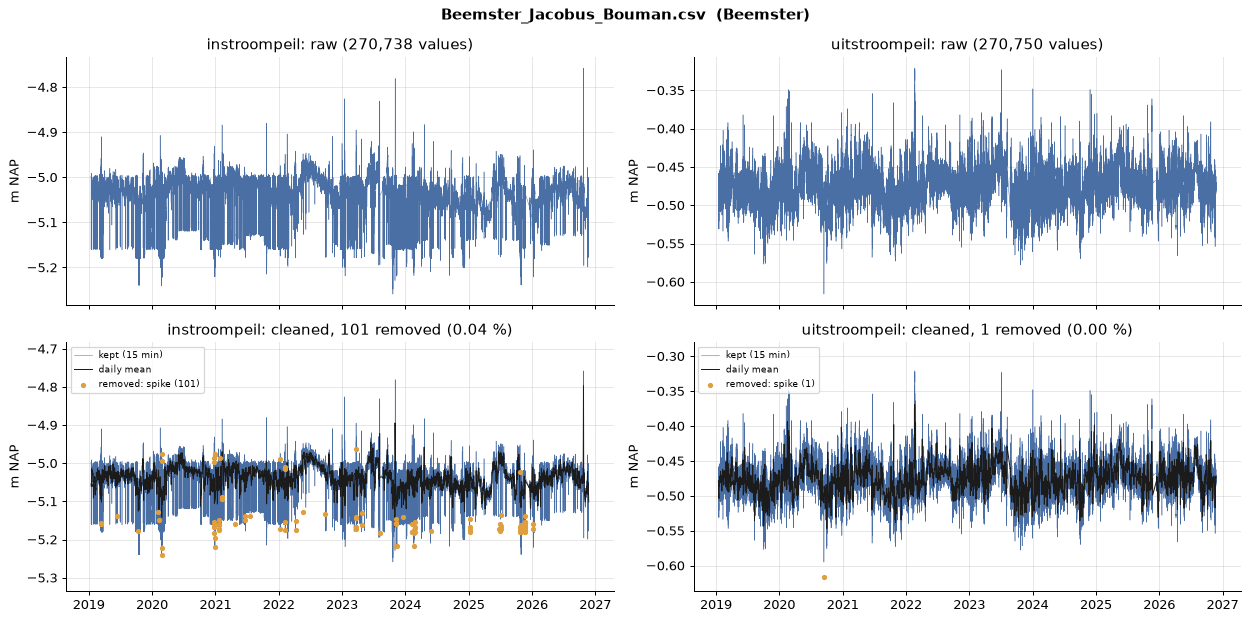

In [8]:
show_file("jacobus_bouman")

### `Beemster_Wouter_Sluis.csv`

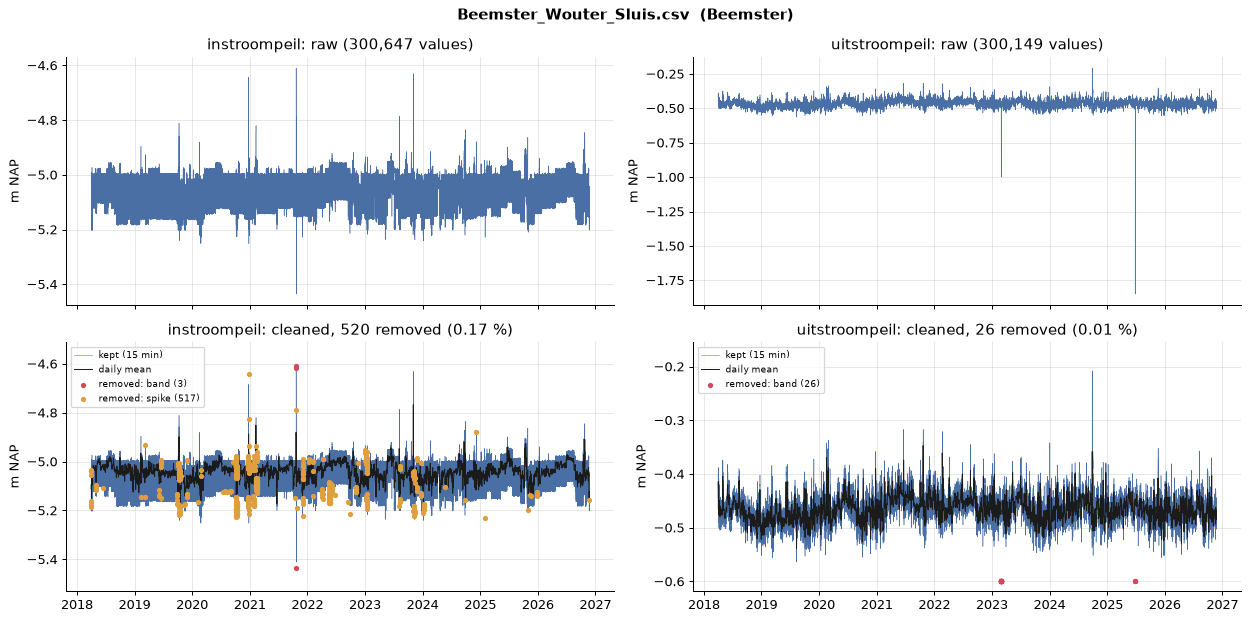

In [9]:
show_file("wouter_sluis")

### `Purmer_Stedelijk.csv`

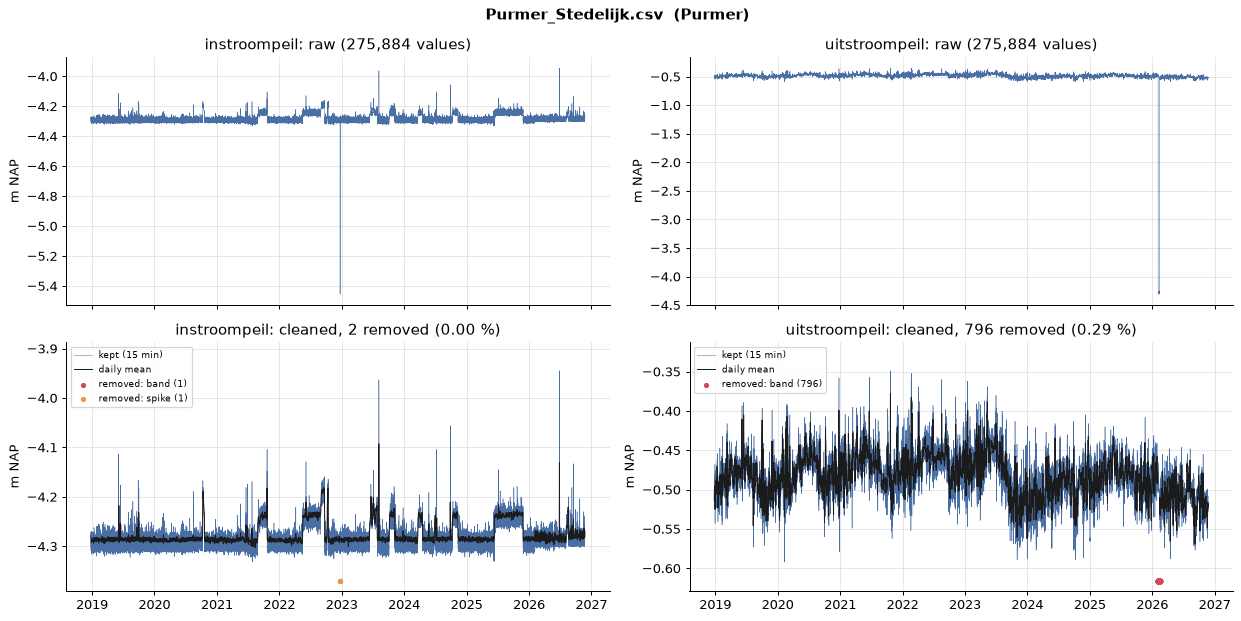

In [10]:
show_file("purmer_stedelijk")

### `Heerhugowaard_Hensbroek.csv`

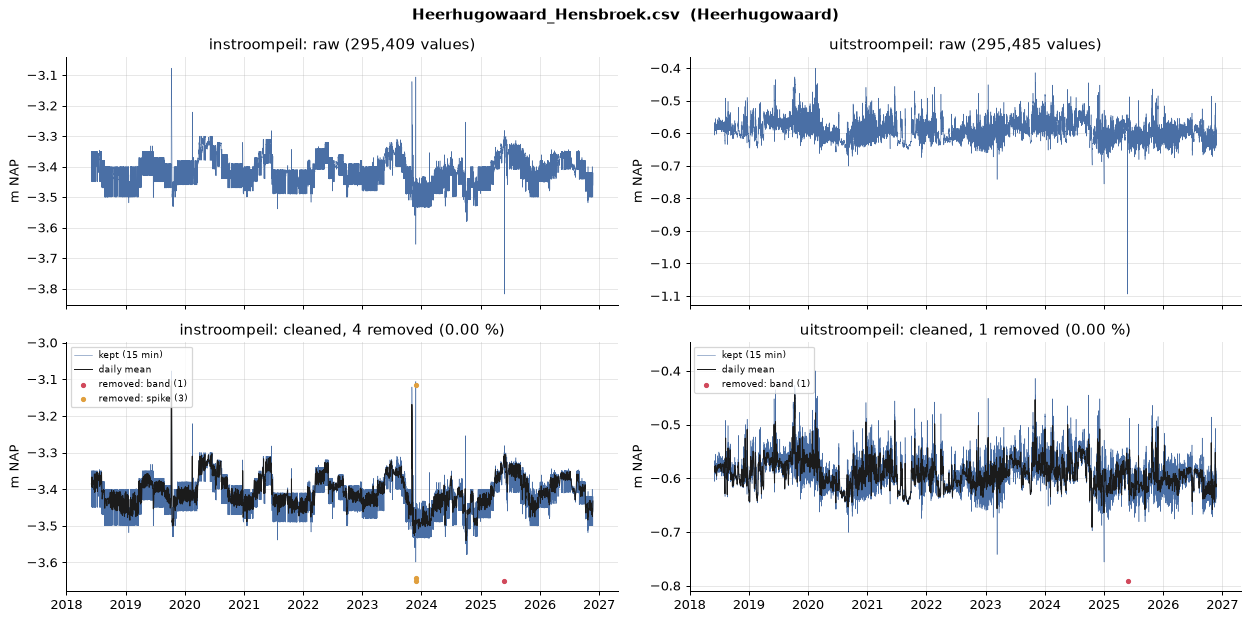

In [11]:
show_file("hensbroek")

### `Heerhugowaard_Huygendijk.csv`

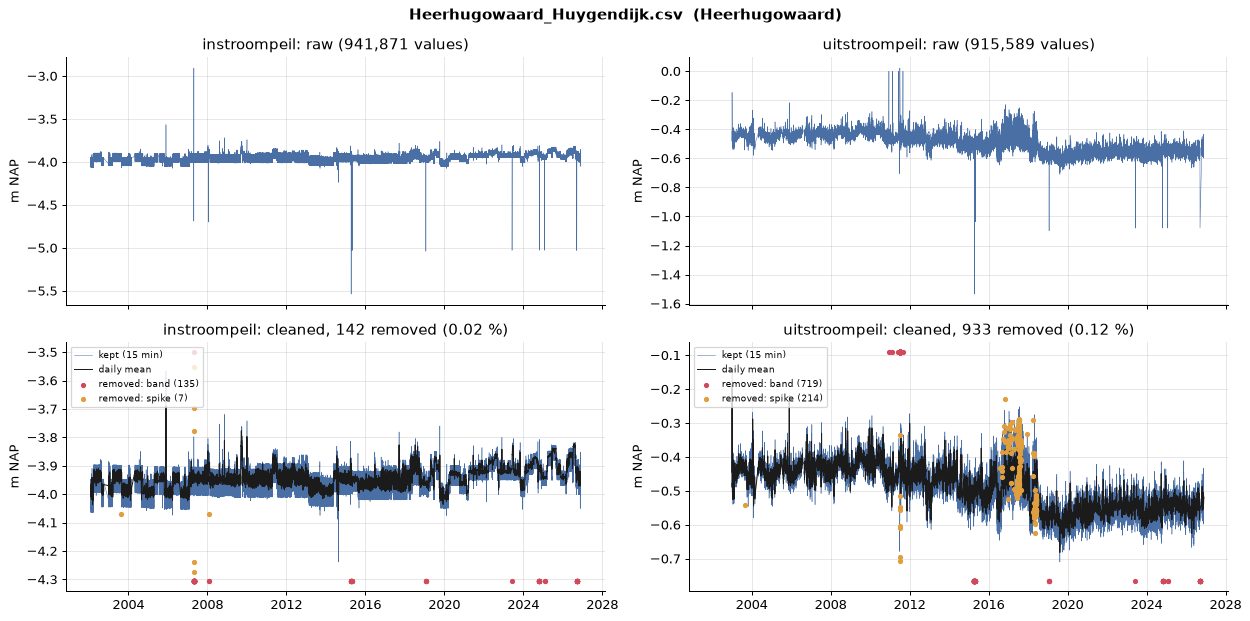

In [12]:
show_file("huygendijk")

## Do the two stations of one polder differ?

If the polder level (instroompeil) or the boezem level (uitstroompeil) differs between the two ends of a water system, a
piezometer near one station could follow that station better. That is the question of the station test in
`docs/experiments/2026-11-24_gemaal-peilen.md`. The comparison uses daily means from 2024 onwards (the calibration years).

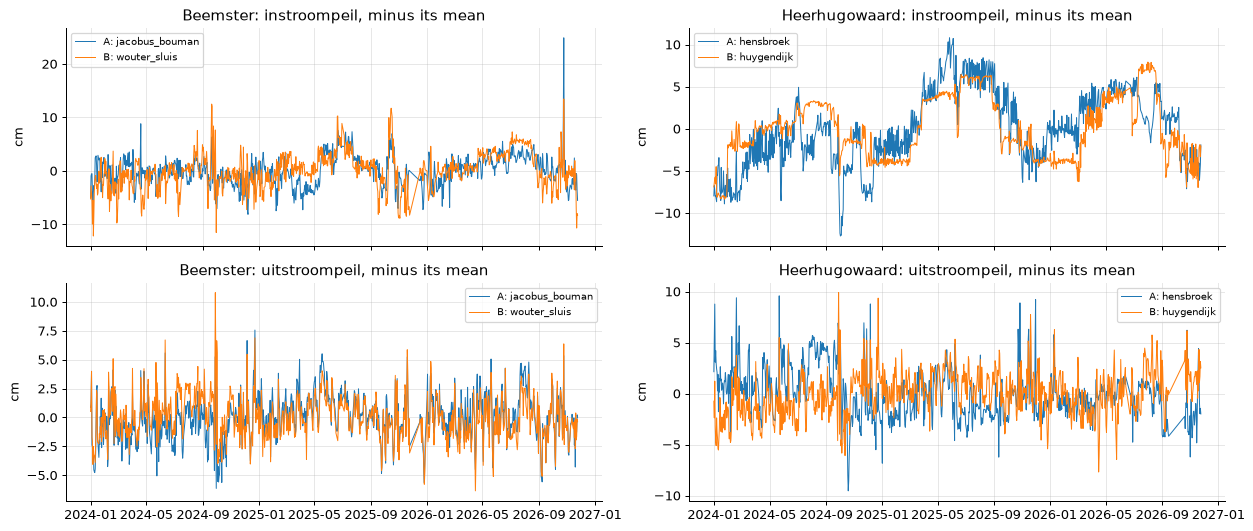

,polder,column,days,r (daily),mean difference (cm),std of the difference (cm),std A (cm),std B (cm)
0,Beemster,instroompeil,1026,0.42,-0.2,3.4,2.8,3.4
1,Beemster,uitstroompeil,1026,0.83,-0.8,1.1,2.0,1.9
2,Heerhugowaard,instroompeil,1047,0.67,48.9,3.4,4.4,3.7
3,Heerhugowaard,uitstroompeil,1013,0.14,-4.8,3.0,2.5,2.2


In [13]:
pairs = {"Beemster": ("jacobus_bouman", "wouter_sluis"), "Heerhugowaard": ("hensbroek", "huygendijk")}
rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharex="col")
for i, (polder, (a, b)) in enumerate(pairs.items()):
    for j, col in enumerate(stresses.COLUMNS):
        both = pd.concat([DAILY[a][col], DAILY[b][col]], axis=1, keys=[a, b]).loc["2024":].dropna()
        anomalies = both - both.mean()
        rows.append({"polder": polder, "column": col, "days": len(both),
                     "r (daily)": round(both.corr().iloc[0, 1], 2),
                     "mean difference (cm)": round(100 * (both[a] - both[b]).mean(), 1),
                     "std of the difference (cm)": round(100 * (anomalies[a] - anomalies[b]).std(), 1),
                     "std A (cm)": round(100 * both[a].std(), 1), "std B (cm)": round(100 * both[b].std(), 1)})
        ax = axes[j, i]
        ax.plot(anomalies.index, 100 * anomalies[a], lw=0.8, label=f"A: {a}")
        ax.plot(anomalies.index, 100 * anomalies[b], lw=0.8, label=f"B: {b}")
        ax.set_title(f"{polder}: {col}, minus its mean")
        ax.set_ylabel("cm")
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
pd.DataFrame(rows)